# Phân tích dữ liệu mua sắm của khách hàng Mall Customers

Dữ liệu gồm các thông tin: Giới tính (Gender), Tuổi (Age), Thu nhập hằng năm (Annual Income - đơn vị: nghìn đô) và Số điểm mua sắm (Spending Score - từ 1 đến 100).

Dữ liệu được đọc trực tiếp từ file CSV chia sẻ trên Google Drive.

## 1. Nhập dữ liệu, thống kê các thông tin cơ bản, xử lý dữ liệu bị thiếu

### 1.1. Nhập dữ liệu từ Google Drive

In [1]:
print("Họ và tên: Lê Quốc Trung - MSSV: 6451071082")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

file_id = "1bsPcz8nZOMPcF3eVVs-EfmDRsqfjjUcC"
url = f"https://drive.google.com/uc?export=download&id={file_id}"

df = pd.read_csv(url)

# Loại bỏ khoảng trắng thừa ở tên cột (nếu có)
df.columns = df.columns.str.strip()

print("Đã đọc dữ liệu thành công!")
df.head()

Họ và tên: Lê Quốc Trung - MSSV: 6451071082
Đã đọc dữ liệu thành công!


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


### 1.2. Thống kê các thông tin cơ bản

In [2]:
print("Họ và tên: Lê Quốc Trung - MSSV: 6451071082")

print("Kích thước dữ liệu (số dòng, số cột):", df.shape)
print("\nTên các cột:", list(df.columns))
print("\nThông tin kiểu dữ liệu:")
df.info()

Họ và tên: Lê Quốc Trung - MSSV: 6451071082
Kích thước dữ liệu (số dòng, số cột): (200, 5)

Tên các cột: ['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Thông tin kiểu dữ liệu:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [3]:
print("Họ và tên: Lê Quốc Trung - MSSV: 6451071082")

# Thống kê mô tả cho các thuộc tính số: count, mean, std, min, tứ phân vị, max
print("Thống kê các thuộc tính số:")
print(df.describe())

# Thống kê thuộc tính phân loại (Gender)
print("\nSố lượng khách hàng theo giới tính:")
print(df['Gender'].value_counts())

Họ và tên: Lê Quốc Trung - MSSV: 6451071082
Thống kê các thuộc tính số:
       CustomerID         Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000  200.000000          200.000000              200.000000
mean   100.500000   38.850000           60.560000               50.200000
std     57.879185   13.969007           26.264721               25.823522
min      1.000000   18.000000           15.000000                1.000000
25%     50.750000   28.750000           41.500000               34.750000
50%    100.500000   36.000000           61.500000               50.000000
75%    150.250000   49.000000           78.000000               73.000000
max    200.000000   70.000000          137.000000               99.000000

Số lượng khách hàng theo giới tính:
Gender
Female    112
Male       88
Name: count, dtype: int64


### 1.3. Kiểm tra và xử lý dữ liệu bị thiếu

In [4]:
print("Họ và tên: Lê Quốc Trung - MSSV: 6451071082")

# Kiểm tra dữ liệu bị thiếu
print("Số giá trị bị thiếu ở mỗi cột:")
print(df.isnull().sum())
print("\nTổng số giá trị bị thiếu:", df.isnull().sum().sum())

# Xử lý dữ liệu bị thiếu:
# - Thuộc tính số: điền bằng giá trị trung vị (median)
# - Thuộc tính phân loại: điền bằng giá trị xuất hiện nhiều nhất (mode)
for col in df.columns:
    if df[col].isnull().any():
        if pd.api.types.is_numeric_dtype(df[col]):
            df[col] = df[col].fillna(df[col].median())
        else:
            df[col] = df[col].fillna(df[col].mode()[0])

print("\nSau khi xử lý, số giá trị bị thiếu ở mỗi cột:")
print(df.isnull().sum())

# Kiểm tra thêm dữ liệu trùng lặp
print("\nSố dòng bị trùng lặp:", df.duplicated().sum())

Họ và tên: Lê Quốc Trung - MSSV: 6451071082
Số giá trị bị thiếu ở mỗi cột:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Tổng số giá trị bị thiếu: 0

Sau khi xử lý, số giá trị bị thiếu ở mỗi cột:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Số dòng bị trùng lặp: 0


## 2. Sử dụng biểu đồ tần suất (Histogram) để biểu diễn phân phối của lần lượt các thuộc tính Tuổi, Thu nhập hằng năm và Số điểm mua sắm

Họ và tên: Lê Quốc Trung - MSSV: 6451071082


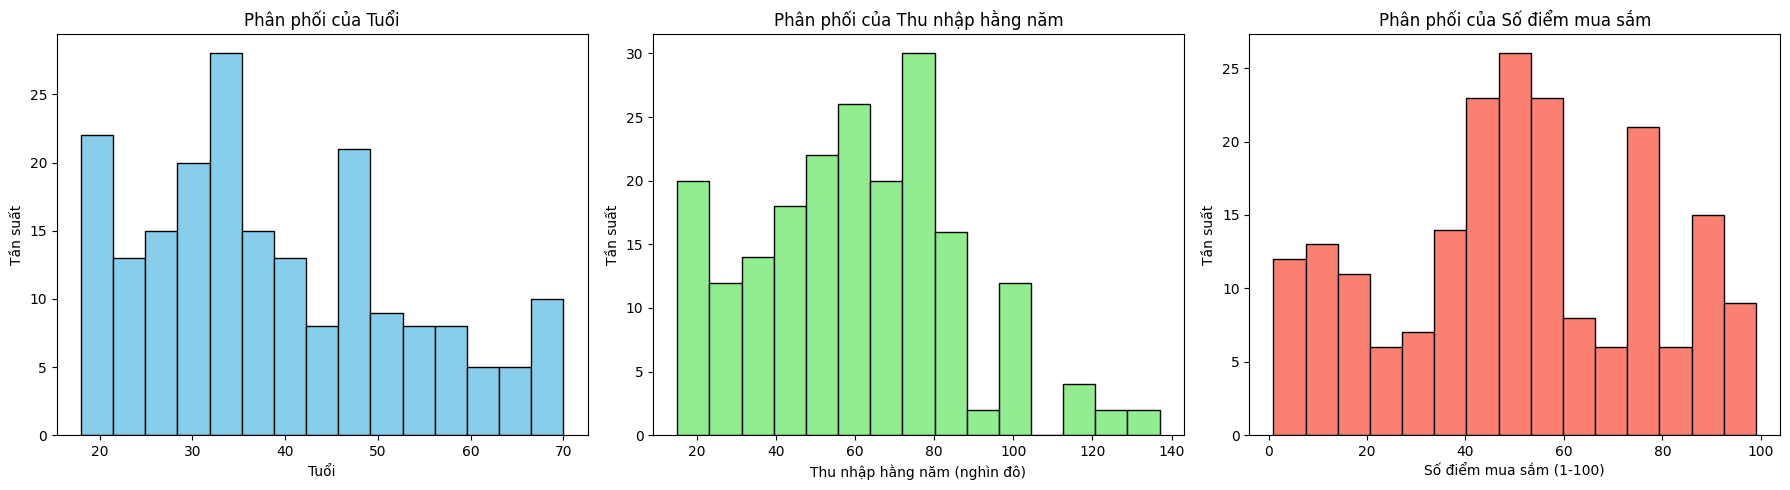

In [5]:
print("Họ và tên: Lê Quốc Trung - MSSV: 6451071082")

columns = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
titles = ['Phân phối của Tuổi', 'Phân phối của Thu nhập hằng năm', 'Phân phối của Số điểm mua sắm']
xlabels = ['Tuổi', 'Thu nhập hằng năm (nghìn đô)', 'Số điểm mua sắm (1-100)']
colors = ['skyblue', 'lightgreen', 'salmon']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col, title, xlabel, color in zip(axes, columns, titles, xlabels, colors):
    ax.hist(df[col], bins=15, color=color, edgecolor='black')
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Tần suất')

plt.tight_layout()
plt.show()